# 03. Bagging and random forests

**Bagging** (bootstrap aggregating, Breiman 1996): fit B deep trees, each to a bootstrap resample, and
average them. If each tree has variance $\sigma^2$ and pairwise correlation $\rho$, the average has variance
$$\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2.$$
More trees remove the second term; only **decorrelating** the trees reduces the first. Random forests
(Breiman 2001) decorrelate by letting each split consider only a random subset of `max_features` features.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))
# a small, readable working set used throughout
F = ["up_stw_dwf_m3d_per_km2", "up_spill_hours_per_km2", "up_lc_urban", "up_lc_arable",
     "up_lc_improved_grass", "up_lc_seminatural", "up_area_km2", "local_n_private_sewage"]
d = t[t.phos_good.notna()].reset_index(drop=True)
X, y = d[F].to_numpy(float), d.phos_good.to_numpy(int)
groups = d.management_catchment.to_numpy()
print(X.shape, "share with good phosphate:", y.mean().round(3))

(3706, 8) share with good phosphate: 0.484


In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, groups))

def bagged_oof(B, max_features=None, seed=0):
    rng = np.random.default_rng(seed); oof = np.zeros(len(y))
    for a, b in folds:
        P = np.zeros(len(b))
        for k in range(B):
            i = rng.choice(a, len(a), replace=True)
            m = DecisionTreeClassifier(max_features=max_features, min_samples_leaf=3,
                                       random_state=int(rng.integers(1e9))).fit(X[i], y[i])
            P += m.predict_proba(X[b])[:, 1]
        oof[b] = P / B
    return roc_auc_score(y, oof)

rows = [(B, bagged_oof(B), bagged_oof(B, max_features=3)) for B in [1, 5, 20, 60, 150]]
r = pd.DataFrame(rows, columns=["trees", "bagging (all 8 features)", "random forest (3 of 8)"]); r.round(3)

,trees,bagging (all 8 features),random forest (3 of 8)
0,1,0.677,0.678
1,5,0.771,0.777
2,20,0.789,0.798
3,60,0.797,0.806
4,150,0.800,0.807


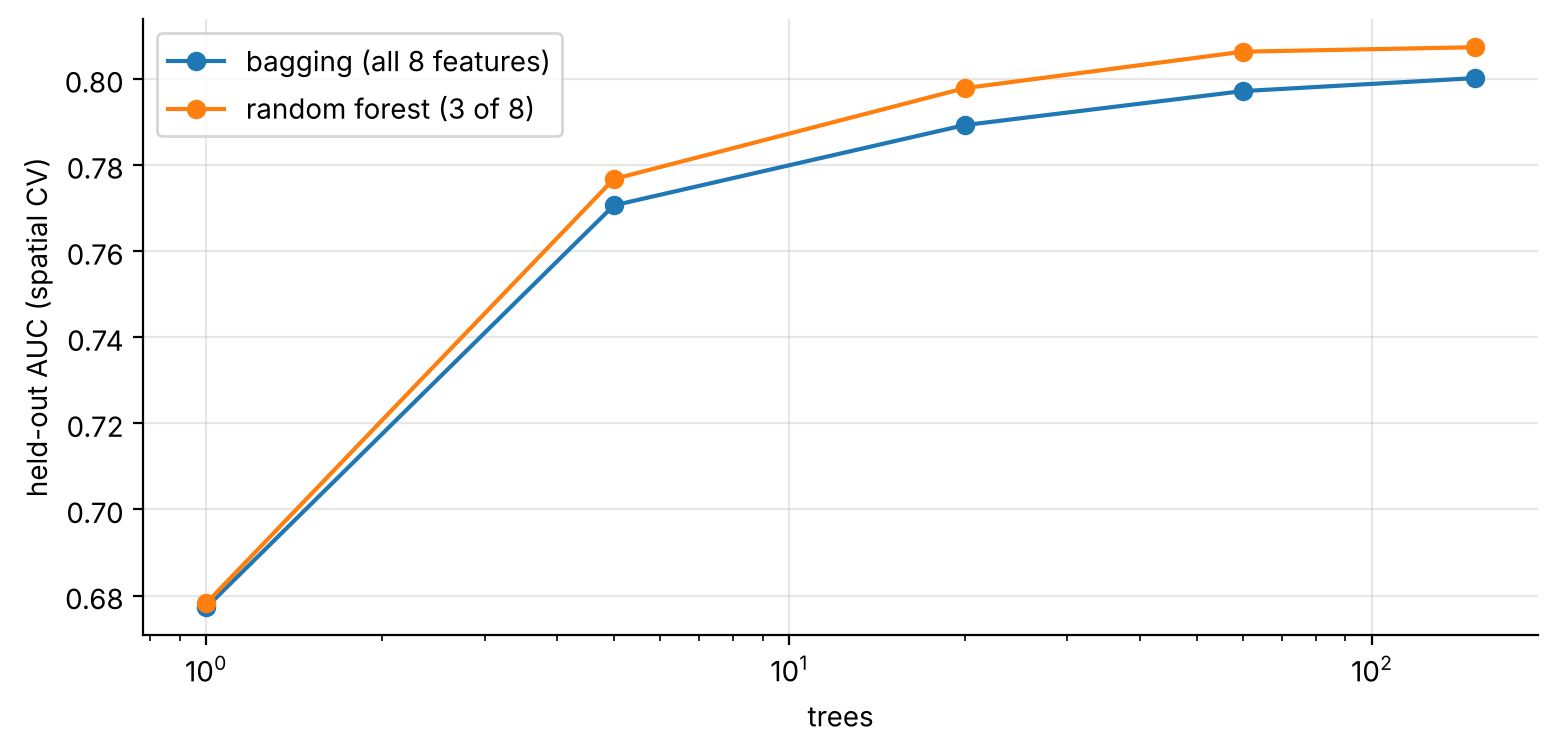

In [3]:
plt.plot(r.trees, r.iloc[:, 1], marker="o", label=r.columns[1]); plt.plot(r.trees, r.iloc[:, 2], marker="o", label=r.columns[2])
plt.xscale("log"); plt.xlabel("trees"); plt.ylabel("held-out AUC (spatial CV)"); plt.legend(); plt.show()

One deep tree scores 0.68. Averaging 20 lifts that to about 0.79-0.80, and restricting each split to 3 of 8
features adds about 0.01 more. Adding trees never overfits, it only stops helping.

## Out-of-bag estimates

Each bootstrap sample leaves out about $(1 - 1/n)^n \approx e^{-1} \approx 37\%$ of rows. Scoring each
row only with the trees that did not see it gives a free validation estimate.

In [4]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(400, min_samples_leaf=3, oob_score=True, n_jobs=-1, random_state=0).fit(X, y)
oob_auc = roc_auc_score(y, rf.oob_decision_function_[:, 1])
sp = np.zeros(len(y))
for a, b in folds:
    sp[b] = RandomForestClassifier(400, min_samples_leaf=3, n_jobs=-1, random_state=0).fit(X[a], y[a]).predict_proba(X[b])[:, 1]
print(f"OOB AUC {oob_auc:.3f}  vs  spatial-CV AUC {roc_auc_score(y, sp):.3f}")

OOB AUC 0.824  vs  spatial-CV AUC 0.810


Here OOB says 0.824 and spatial CV 0.810. OOB is valid when rows are independent. Rivers are not: an out-of-bag water body usually has its
upstream and downstream neighbours *in* the bag, so OOB is optimistic, just like random-fold CV.
Use it for quick tuning, not for reporting.

## Variance in practice: how much do predictions move?

In [5]:
rng = np.random.default_rng(1); preds_tree, preds_rf = [], []
for k in range(10):
    i = rng.choice(len(y), len(y), replace=True)
    preds_tree.append(DecisionTreeClassifier(min_samples_leaf=3, random_state=k).fit(X[i], y[i]).predict_proba(X)[:, 1])
    preds_rf.append(RandomForestClassifier(200, min_samples_leaf=3, n_jobs=-1, random_state=k).fit(X[i], y[i]).predict_proba(X)[:, 1])
print("mean SD of a river's prediction across resamples: tree", np.std(preds_tree, 0).mean().round(3),
      "| forest", np.std(preds_rf, 0).mean().round(3))

mean SD of a river's prediction across resamples: tree 0.236 | forest 0.096
